In [ ]:
#Cell 1 — توليد البيانات والمكتبات
import numpy as np
import pandas as pd
import scipy.stats as stats
import math
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
N = 120

interarrival_times = np.random.exponential(scale=3.0, size=N)
inspection_times   = np.random.exponential(scale=2.0, size=N)
sorting_times      = np.abs(np.random.normal(loc=1.5, scale=0.3, size=N))
loading_times      = np.random.uniform(low=1.0, high=3.0, size=N)

df = pd.DataFrame({
    'Package_ID':           range(1, N+1),
    'Interarrival_Time':    interarrival_times.round(4),
    'Inspection_Time':      inspection_times.round(4),
    'Sorting_Time':         sorting_times.round(4),
    'Loading_Time':         loading_times.round(4),
})

print("=" * 60)
print("DA 380 — البيانات جاهزة")
print("=" * 60)
print(f"عدد المشاهدات: {N}")
print(df.head(10).to_string(index=False))

DA 380 — البيانات جاهزة
عدد المشاهدات: 120
 Package_ID  Interarrival_Time  Inspection_Time  Sorting_Time  Loading_Time
          1             1.4078           3.2947        1.4330        2.9810
          2             9.0304           4.5285        1.7142        1.8252
          3             3.9502           0.7655        1.6420        1.7440
          4             2.7388           0.2332        1.4782        2.5528
          5             0.5089           0.5174        1.2460        1.6816
          6             0.5088           1.1141        1.0455        2.8615
          7             0.1795           3.4077        1.3660        2.7168
          8             6.0337           3.9427        1.7569        1.8580
          9             2.7572           0.0140        1.5642        2.5017
         10             3.6938           1.4298        1.1263        2.5091


CELL 2 — Descriptive Statistics
       Interarrival_Time  Inspection_Time  Sorting_Time  Loading_Time
count           120.0000         120.0000      120.0000      120.0000
mean              2.7818           1.8421        1.5078        2.0806
std               2.7145           1.7444        0.3103        0.6229
min               0.0166           0.0101        0.5276        1.0217
25%               0.6620           0.5464        1.2992        1.6109
50%               1.9798           1.3970        1.5227        2.1122
75%               4.2424           2.4438        1.6999        2.6316
max              13.0024           8.4881        2.6558        2.9859
CV                0.9758           0.9470        0.2058        0.2994


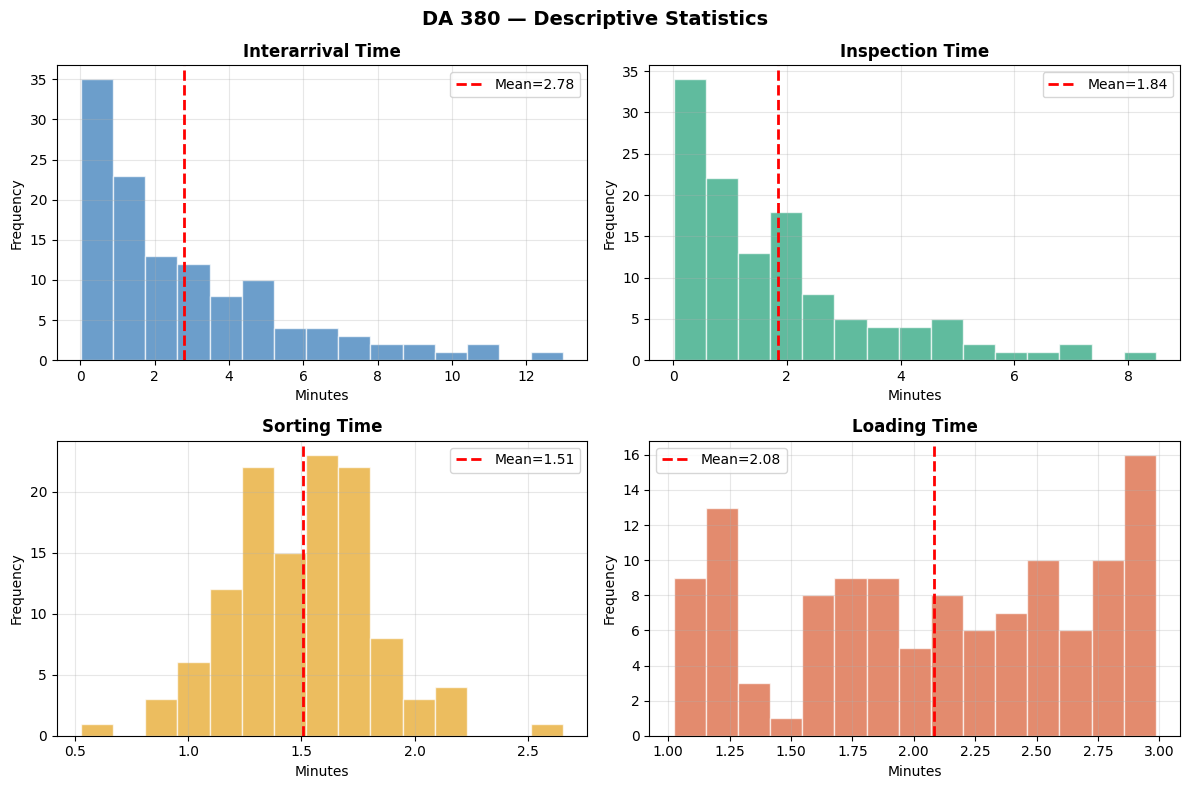


الإحصاء الوصفي الكامل:

Interarrival_Time:
  Mean   = 2.7818
  Std    = 2.7145
  Min    = 0.0166
  Max    = 13.0024
  Median = 1.9798
  CV     = 0.9758

Inspection_Time:
  Mean   = 1.8421
  Std    = 1.7444
  Min    = 0.0101
  Max    = 8.4881
  Median = 1.3969
  CV     = 0.9470

Sorting_Time:
  Mean   = 1.5078
  Std    = 0.3103
  Min    = 0.5276
  Max    = 2.6558
  Median = 1.5227
  CV     = 0.2058

Loading_Time:
  Mean   = 2.0806
  Std    = 0.6229
  Min    = 1.0217
  Max    = 2.9859
  Median = 2.1122
  CV     = 0.2994


In [ ]:
#Cell 2 — Descriptive Statistics
print("=" * 60)
print("CELL 2 — Descriptive Statistics")
print("=" * 60)

cols = ['Interarrival_Time', 'Inspection_Time', 'Sorting_Time', 'Loading_Time']

stats_df = df[cols].describe().round(4)
stats_df.loc['CV'] = (df[cols].std() / df[cols].mean()).round(4)

print(stats_df.to_string())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('DA 380 — Descriptive Statistics', fontsize=14, fontweight='bold')

colors = ['#2E75B6', '#1D9E75', '#E4A11B', '#D85A30']
titles = ['Interarrival Time', 'Inspection Time', 'Sorting Time', 'Loading Time']

for i, (col, color, title) in enumerate(zip(cols, colors, titles)):
    ax = axes[i//2][i%2]
    ax.hist(df[col], bins=15, color=color, alpha=0.7, edgecolor='white')
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean={df[col].mean():.2f}')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Minutes')
    ax.set_ylabel('Frequency')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nالإحصاء الوصفي الكامل:")
for col in cols:
    print(f"\n{col}:")
    print(f"  Mean   = {df[col].mean():.4f}")
    print(f"  Std    = {df[col].std():.4f}")
    print(f"  Min    = {df[col].min():.4f}")
    print(f"  Max    = {df[col].max():.4f}")
    print(f"  Median = {df[col].median():.4f}")
    print(f"  CV     = {df[col].std()/df[col].mean():.4f}")

CELL 3 — Distribution Fitting (KS Test)

Interarrival Time:
Distribution  KS_Statistic  P_Value  Result
 Exponential       0.05666  0.81467 مقبول ✅
     Weibull       0.06019  0.75426 مقبول ✅
       Gamma       0.07132  0.55080 مقبول ✅
   Lognormal       0.07313  0.51861 مقبول ✅
      Normal       0.15317  0.00635 مرفوض ❌
  --> أفضل توزيع: Exponential (p=0.81467)

Inspection Time:
Distribution  KS_Statistic  P_Value  Result
       Gamma       0.05190  0.88614 مقبول ✅
 Exponential       0.05303  0.87052 مقبول ✅
     Weibull       0.05976  0.76183 مقبول ✅
   Lognormal       0.08098  0.39008 مقبول ✅
      Normal       0.14580  0.01087 مرفوض ❌
  --> أفضل توزيع: Gamma (p=0.88614)

Sorting Time:
Distribution  KS_Statistic  P_Value  Result
      Normal       0.05153  0.89109 مقبول ✅
       Gamma       0.05194  0.88566 مقبول ✅
   Lognormal       0.05199  0.88495 مقبول ✅
     Weibull       0.05694  0.81003 مقبول ✅
 Exponential       0.45803  0.00000 مرفوض ❌
  --> أفضل توزيع: Normal (p=0.89109)


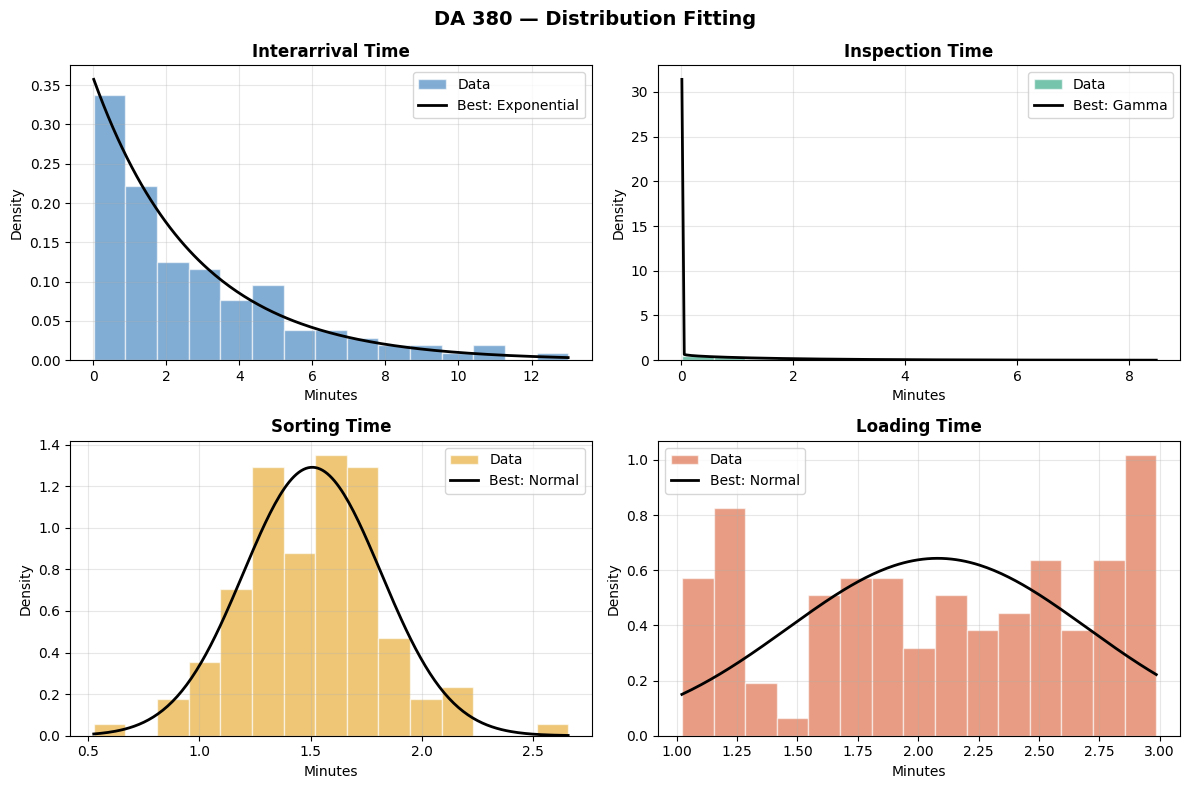

In [ ]:
#Cell 3 — Distribution Fitting (KS Test)
print("=" * 60)
print("CELL 3 — Distribution Fitting (KS Test)")
print("=" * 60)

def fit_distributions(data, name):
    distributions = {
        'Exponential': stats.expon,
        'Normal':      stats.norm,
        'Gamma':       stats.gamma,
        'Lognormal':   stats.lognorm,
        'Weibull':     stats.weibull_min,
    }
    results = []
    for dist_name, dist in distributions.items():
        try:
            params = dist.fit(data, floc=0) if dist_name == 'Exponential' else dist.fit(data)
            ks_stat, p_value = stats.kstest(data, dist.cdf, args=params)
            results.append({
                'Distribution': dist_name,
                'KS_Statistic': round(ks_stat, 5),
                'P_Value':      round(p_value, 5),
                'Result':       'مقبول ✅' if p_value > 0.05 else 'مرفوض ❌'
            })
        except:
            pass
    results_df = pd.DataFrame(results).sort_values('P_Value', ascending=False)
    best = results_df.iloc[0]
    print(f"\n{name}:")
    print(results_df.to_string(index=False))
    print(f"  --> أفضل توزيع: {best['Distribution']} (p={best['P_Value']})")
    return best['Distribution']

best_fits = {}
for col, name in zip(cols, ['Interarrival Time', 'Inspection Time', 'Sorting Time', 'Loading Time']):
    best_fits[col] = fit_distributions(df[col], name)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('DA 380 — Distribution Fitting', fontsize=14, fontweight='bold')

for i, (col, color, title) in enumerate(zip(cols, colors, titles)):
    ax = axes[i//2][i%2]
    ax.hist(df[col], bins=15, density=True, alpha=0.6, color=color, edgecolor='white', label='Data')
    x = np.linspace(df[col].min(), df[col].max(), 200)
    dist = stats.expon if best_fits[col]=='Exponential' else (stats.norm if best_fits[col]=='Normal' else stats.gamma)
    params = dist.fit(df[col], floc=0) if best_fits[col]=='Exponential' else dist.fit(df[col])
    ax.plot(x, dist.pdf(x, *params), 'k-', linewidth=2, label=f'Best: {best_fits[col]}')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Minutes')
    ax.set_ylabel('Density')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

CELL 4 — Queueing Theory M/M/1 & M/M/c

معدل الوصول      λ = 0.3595 طرد/دقيقة (21.57 طرد/ساعة)
معدل الخدمة      μ = 0.5429 طرد/دقيقة (32.57 طرد/ساعة)

────────────────────────────────────────
M/M/1 النتائج:
────────────────────────────────────────
  Traffic Intensity  ρ  = 0.6622
  Avg Queue Length   Lq = 1.2983 طرود
  Avg System Length  L  = 1.9605 طرود
  Avg Wait in Queue  Wq = 3.6114 دقيقة
  Avg Time in System W  = 5.4536 دقيقة
  النظام: مستقر ✅ (ρ < 1)

────────────────────────────────────────
M/M/c مقارنة:
────────────────────────────────────────
    c       ρ      Lq    Wq(min)    W(min)
  ────────────────────────────────────────
  c=1  0.6622  1.2983     3.6114    5.4536
  c=2  0.3311  0.0815     0.2268     2.069
  c=3  0.2207  0.0091     0.0252    1.8673


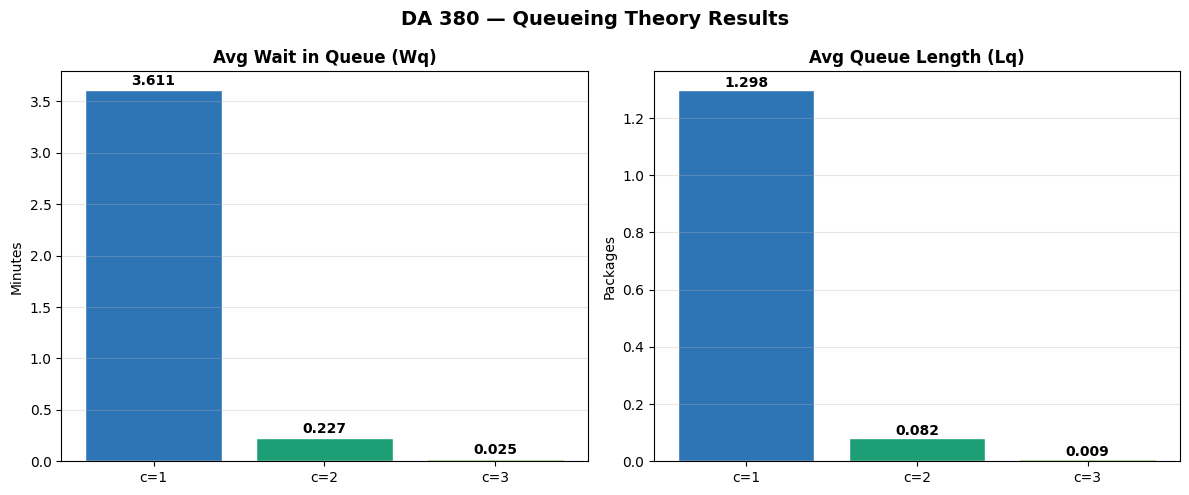


تم الانتهاء بنجاح ✅


In [ ]:
#Cell 4 — Queueing Theory M/M/1 & M/M/c
print("=" * 60)
print("CELL 4 — Queueing Theory M/M/1 & M/M/c")
print("=" * 60)

lambda_rate = 1 / df['Interarrival_Time'].mean()
mu_rate     = 1 / df['Inspection_Time'].mean()

print(f"\nمعدل الوصول      λ = {lambda_rate:.4f} طرد/دقيقة ({lambda_rate*60:.2f} طرد/ساعة)")
print(f"معدل الخدمة      μ = {mu_rate:.4f} طرد/دقيقة ({mu_rate*60:.2f} طرد/ساعة)")

# ── M/M/1 ──
rho = lambda_rate / mu_rate
Lq  = rho**2 / (1 - rho)
L   = rho / (1 - rho)
Wq  = Lq / lambda_rate
W   = L  / lambda_rate

print(f"\n{'─'*40}")
print("M/M/1 النتائج:")
print(f"{'─'*40}")
print(f"  Traffic Intensity  ρ  = {rho:.4f}")
print(f"  Avg Queue Length   Lq = {Lq:.4f} طرود")
print(f"  Avg System Length  L  = {L:.4f} طرود")
print(f"  Avg Wait in Queue  Wq = {Wq:.4f} دقيقة")
print(f"  Avg Time in System W  = {W:.4f} دقيقة")
print(f"  النظام: {'مستقر ✅ (ρ < 1)' if rho < 1 else 'غير مستقر ❌'}")

# ── M/M/c ──
def mm_c(lam, mu, c):
    rho = lam / (c * mu)
    if rho >= 1:
        return None
    sum_terms = sum([(c*rho)**n / math.factorial(n) for n in range(c)])
    last_term  = (c*rho)**c / (math.factorial(c) * (1-rho))
    P0         = 1 / (sum_terms + last_term)
    Erlang_C   = (P0 * (c*rho)**c) / (math.factorial(c) * (1-rho))
    Lq = Erlang_C * rho / (1-rho)
    Wq = Lq / lam
    W  = Wq + 1/mu
    L  = lam * W
    return {'c':c, 'rho':round(rho,4), 'Lq':round(Lq,4), 'Wq':round(Wq,4), 'W':round(W,4), 'L':round(L,4)}

print(f"\n{'─'*40}")
print("M/M/c مقارنة:")
print(f"{'─'*40}")
print(f"  {'c':>3}  {'ρ':>6}  {'Lq':>6}  {'Wq(min)':>9}  {'W(min)':>8}")
print(f"  {'─'*40}")
mmc_results = []
for c in [1, 2, 3]:
    r = mm_c(lambda_rate, mu_rate, c)
    if r:
        print(f"  c={c}  {r['rho']:>6}  {r['Lq']:>6}  {r['Wq']:>9}  {r['W']:>8}")
        mmc_results.append(r)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('DA 380 — Queueing Theory Results', fontsize=14, fontweight='bold')

servers = [r['c'] for r in mmc_results]
wq_vals = [r['Wq'] for r in mmc_results]
lq_vals = [r['Lq'] for r in mmc_results]

axes[0].bar([f'c={s}' for s in servers], wq_vals, color=['#2E75B6','#1D9E75','#97C459'], edgecolor='white')
axes[0].set_title('Avg Wait in Queue (Wq)', fontweight='bold')
axes[0].set_ylabel('Minutes')
axes[0].grid(alpha=0.3, axis='y')
for i, v in enumerate(wq_vals):
    axes[0].text(i, v+0.05, f'{v:.3f}', ha='center', fontweight='bold')

axes[1].bar([f'c={s}' for s in servers], lq_vals, color=['#2E75B6','#1D9E75','#97C459'], edgecolor='white')
axes[1].set_title('Avg Queue Length (Lq)', fontweight='bold')
axes[1].set_ylabel('Packages')
axes[1].grid(alpha=0.3, axis='y')
for i, v in enumerate(lq_vals):
    axes[1].text(i, v+0.01, f'{v:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("تم الانتهاء بنجاح ✅")
print("="*60)

In [1]:
#Team 3: Raghad + Hind
# ════════════════════════════════════════════
# Team 3: Simulation & System Design
# Raghad + Hind — DA 380
# Full Discrete-Event Simulation Model
# ════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import math

np.random.seed(42)
random.seed(42)

# ════════════════════════════════════════════
# إعدادات النظام
# ════════════════════════════════════════════
class Config:
    ARRIVAL_MEAN     = 3.0    # متوسط وقت الوصول (دقيقة)
    INSPECT_MEAN     = 2.0    # متوسط وقت الفحص
    SORT_MEAN        = 1.5    # متوسط وقت الفرز
    SORT_STD         = 0.3    # انحراف معياري الفرز
    LOAD_MIN         = 1.0    # أدنى وقت تحميل
    LOAD_MAX         = 3.0    # أعلى وقت تحميل
    EXPRESS_PROB     = 0.30   # نسبة طرود Express
    SIM_DURATION     = 480    # مدة المحاكاة (8 ساعات)
    WARMUP           = 60     # فترة الإحماء
    MTTF             = 120    # متوسط وقت بين الأعطال
    MTTR             = 15     # متوسط وقت الإصلاح
    BREAK_TIME       = 10     # وقت الاستراحة بين المناوبات

print("=" * 60)
print("Team 3: Simulation & System Design — DA 380")
print("=" * 60)
print(f"مدة المحاكاة : {Config.SIM_DURATION} دقيقة (8 ساعات)")
print(f"فترة Warm-up : {Config.WARMUP} دقيقة")
print(f"Express %    : {Config.EXPRESS_PROB*100}%")
print(f"MTTF         : {Config.MTTF} دقيقة")
print(f"MTTR         : {Config.MTTR} دقيقة")

Team 3: Simulation & System Design — DA 380
مدة المحاكاة : 480 دقيقة (8 ساعات)
فترة Warm-up : 60 دقيقة
Express %    : 30.0%
MTTF         : 120 دقيقة
MTTR         : 15 دقيقة


In [2]:
# ════════════════════════════════════════════
# Cell 2: محرك المحاكاة — Simulation Engine
# ════════════════════════════════════════════

class LogisticsSimulation:
    def __init__(self, cfg, n_inspectors=1, seed=None):
        self.cfg          = cfg
        self.n_inspectors = n_inspectors
        if seed is not None:
            np.random.seed(seed)
            random.seed(seed)
        self.reset()

    def reset(self):
        self.clock            = 0.0
        self.events           = []
        self.express_queue    = []
        self.standard_queue   = []
        self.sort_queue       = []
        self.load_queue       = []
        self.inspectors_busy  = 0
        self.sorter_busy      = False
        self.loader_busy      = False
        self.machine_broken   = False
        self.in_warmup        = True
        self.system_times     = []
        self.wait_times       = []
        self.queue_samples    = []
        self.throughput       = 0
        self.pkg_data         = {}

    def schedule(self, time, etype, pid=None, ptype=None):
        self.events.append((time, etype, pid, ptype))
        self.events.sort(key=lambda x: x[0])

    def in_break(self, t):
        return 240 <= t <= 250  # استراحة بين الشيفتين

    def run(self):
        pkg_counter = 0

        # جدولة أول وصول وأول عطل
        self.schedule(
            np.random.exponential(self.cfg.ARRIVAL_MEAN), 'ARRIVAL')
        self.schedule(
            np.random.exponential(self.cfg.MTTF), 'BREAKDOWN')

        while self.events and self.clock <= self.cfg.SIM_DURATION:
            t, etype, pid, ptype = self.events.pop(0)
            self.clock = t

            # تحقق من فترة Warm-up
            if self.in_warmup and self.clock >= self.cfg.WARMUP:
                self.in_warmup = False

            # ── وصول طرد ──
            if etype == 'ARRIVAL':
                pkg_counter += 1
                pid   = pkg_counter
                ptype = 'Express' if random.random() < self.cfg.EXPRESS_PROB \
                        else 'Standard'
                self.pkg_data[pid] = {
                    'arrive': self.clock,
                    'type':   ptype,
                    'wait':   0.0
                }

                # هل المفتش متاح؟
                if (not self.in_break(self.clock) and
                        self.inspectors_busy < self.n_inspectors):
                    self.inspectors_busy += 1
                    svc = np.random.exponential(self.cfg.INSPECT_MEAN)
                    self.schedule(self.clock + svc, 'INSPECT_END', pid, ptype)
                else:
                    # إضافة للطابور حسب الأولوية
                    if ptype == 'Express':
                        self.express_queue.append((pid, ptype, self.clock))
                    else:
                        self.standard_queue.append((pid, ptype, self.clock))

                # جدولة الوصول التالي
                self.schedule(
                    self.clock + np.random.exponential(self.cfg.ARRIVAL_MEAN),
                    'ARRIVAL')

                # تسجيل طول الطابور
                if not self.in_warmup:
                    q = len(self.express_queue) + len(self.standard_queue)
                    self.queue_samples.append(q)

            # ── انتهاء الفحص ──
            elif etype == 'INSPECT_END' and pid:
                # خدمة الطرد التالي (Express أولوية)
                next_pkg = None
                if self.express_queue:
                    next_pkg = self.express_queue.pop(0)
                elif self.standard_queue:
                    next_pkg = self.standard_queue.pop(0)

                if next_pkg and not self.in_break(self.clock):
                    npid, nptype, qarrive = next_pkg
                    self.pkg_data[npid]['wait'] += self.clock - qarrive
                    svc = np.random.exponential(self.cfg.INSPECT_MEAN)
                    self.schedule(self.clock + svc, 'INSPECT_END', npid, nptype)
                else:
                    self.inspectors_busy -= 1
                    if next_pkg:
                        self.express_queue.insert(0, next_pkg)

                # إرسال للفرز
                if not self.machine_broken and not self.sorter_busy:
                    self.sorter_busy = True
                    svc = abs(np.random.normal(
                        self.cfg.SORT_MEAN, self.cfg.SORT_STD))
                    self.schedule(self.clock + svc, 'SORT_END', pid, ptype)
                else:
                    self.sort_queue.append((pid, ptype, self.clock))

            # ── انتهاء الفرز ──
            elif etype == 'SORT_END' and pid:
                if self.sort_queue and not self.machine_broken:
                    npid, nptype, qarrive = self.sort_queue.pop(0)
                    svc = abs(np.random.normal(
                        self.cfg.SORT_MEAN, self.cfg.SORT_STD))
                    self.schedule(self.clock + svc, 'SORT_END', npid, nptype)
                else:
                    self.sorter_busy = False

                if not self.loader_busy:
                    self.loader_busy = True
                    svc = random.uniform(self.cfg.LOAD_MIN, self.cfg.LOAD_MAX)
                    self.schedule(self.clock + svc, 'LOAD_END', pid, ptype)
                else:
                    self.load_queue.append((pid, ptype, self.clock))

            # ── انتهاء التحميل ──
            elif etype == 'LOAD_END' and pid:
                if self.load_queue:
                    npid, nptype, _ = self.load_queue.pop(0)
                    svc = random.uniform(self.cfg.LOAD_MIN, self.cfg.LOAD_MAX)
                    self.schedule(self.clock + svc, 'LOAD_END', npid, nptype)
                else:
                    self.loader_busy = False

                if not self.in_warmup and pid in self.pkg_data:
                    d = self.pkg_data[pid]
                    if 'arrive' in d:
                        sys_t = self.clock - d['arrive']
                        self.system_times.append(sys_t)
                        self.wait_times.append(d.get('wait', 0))
                        self.throughput += 1

            # ── عطل الماكينة ──
            elif etype == 'BREAKDOWN':
                self.machine_broken = True
                repair = np.random.exponential(self.cfg.MTTR)
                self.schedule(self.clock + repair, 'REPAIR')

            # ── إصلاح الماكينة ──
            elif etype == 'REPAIR':
                self.machine_broken = False
                self.schedule(
                    self.clock + np.random.exponential(self.cfg.MTTF),
                    'BREAKDOWN')
                if self.sort_queue and not self.sorter_busy:
                    npid, nptype, _ = self.sort_queue.pop(0)
                    self.sorter_busy = True
                    svc = abs(np.random.normal(
                        self.cfg.SORT_MEAN, self.cfg.SORT_STD))
                    self.schedule(self.clock + svc, 'SORT_END', npid, nptype)

        return {
            'avg_system_time':  np.mean(self.system_times) if self.system_times else 0,
            'avg_wait_time':    np.mean(self.wait_times)   if self.wait_times   else 0,
            'avg_queue_length': np.mean(self.queue_samples) if self.queue_samples else 0,
            'throughput':       self.throughput,
        }

print("✅ Simulation Engine جاهز")

✅ Simulation Engine جاهز


In [4]:
# ════════════════════════════════════════════
# Cell 3: تشغيل 30 تكرار — Design A vs B
# ════════════════════════════════════════════

N_REPS = 30
results_A = []
results_B = []

print("🔁 تشغيل Design A (1 مفتش)...")
for rep in range(N_REPS):
    sim = LogisticsSimulation(Config, n_inspectors=1, seed=rep*100)
    results_A.append(sim.run())

print("🔁 تشغيل Design B (2 مفتشين)...")
for rep in range(N_REPS):
    sim = LogisticsSimulation(Config, n_inspectors=2, seed=rep*100)
    results_B.append(sim.run())

df_A = pd.DataFrame(results_A)
df_B = pd.DataFrame(results_B)

print("\n" + "=" * 60)
print("النتائج — Design A (1 مفتش):")
print("=" * 60)
print(df_A.describe().round(3).to_string())

print("\n" + "=" * 60)
print("النتائج — Design B (2 مفتشين):")
print("=" * 60)
print(df_B.describe().round(3).to_string())

🔁 تشغيل Design A (1 مفتش)...
🔁 تشغيل Design B (2 مفتشين)...

النتائج — Design A (1 مفتش):
       avg_system_time  avg_wait_time  avg_queue_length  throughput
count           30.000         30.000            30.000      30.000
mean            18.472          4.946             2.371     143.067
std              9.781          2.950             1.206      12.504
min             10.085          1.717             0.844     117.000
25%             12.362          2.824             1.542     134.250
50%             16.278          4.122             1.990     144.000
75%             19.774          6.416             2.961     151.750
max             60.202         15.275             6.549     170.000

النتائج — Design B (2 مفتشين):
       avg_system_time  avg_wait_time  avg_queue_length  throughput
count           30.000         30.000            30.000      30.000
mean            13.666          0.586             0.390     142.267
std              6.220          0.257             0.139      1

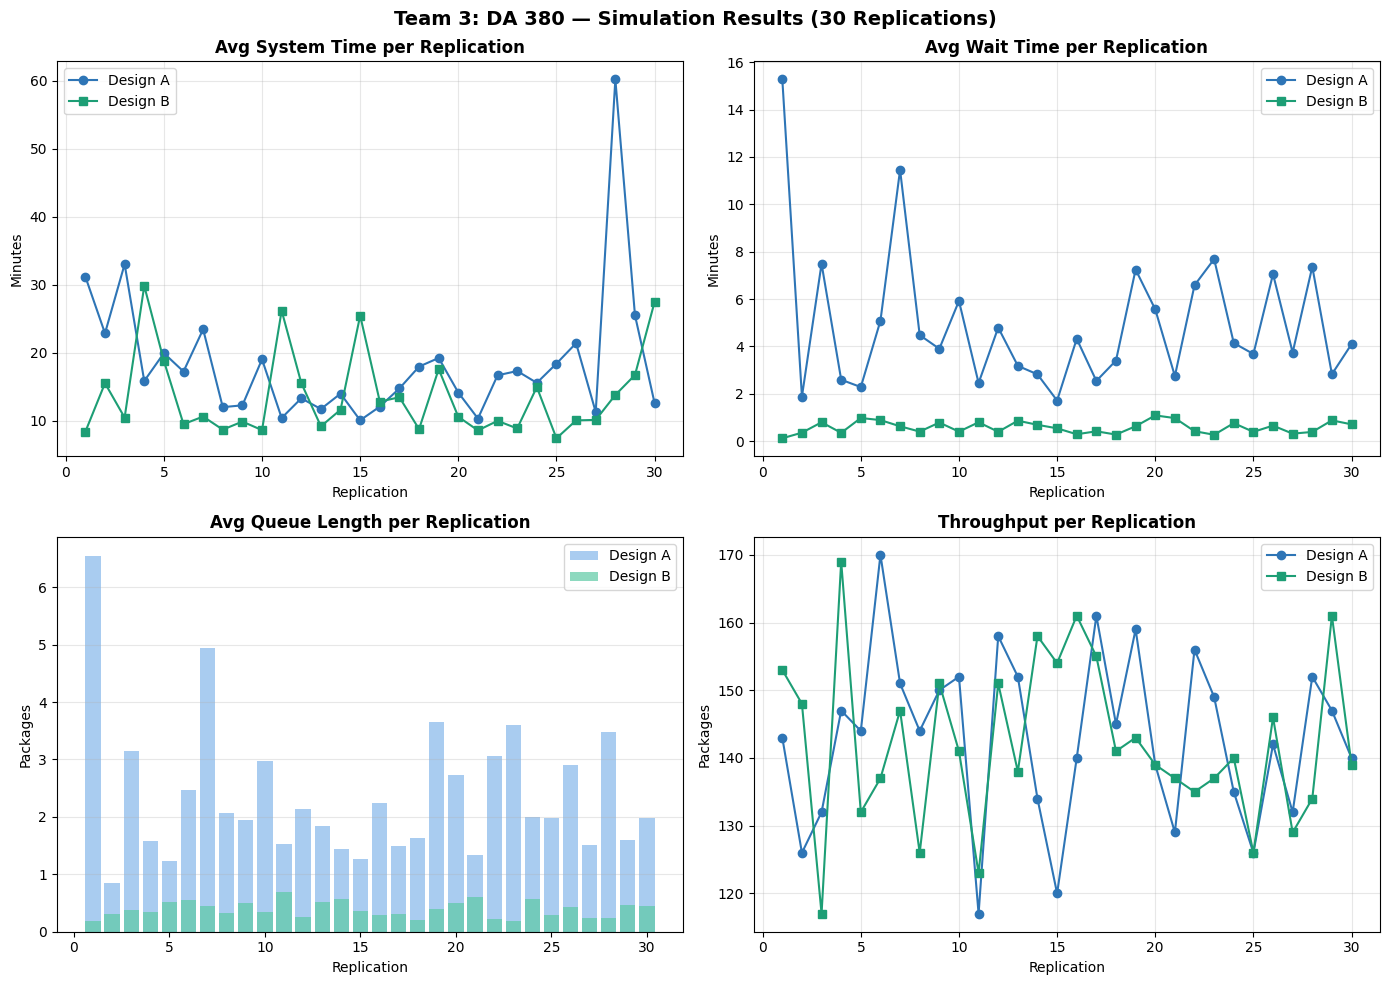

✅ تم حفظ الرسم: DA380_Simulation_Results.png


In [5]:
# ════════════════════════════════════════════
# Cell 4: رسوم نتائج المحاكاة
# ════════════════════════════════════════════

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Team 3: DA 380 — Simulation Results (30 Replications)',
             fontsize=14, fontweight='bold')

reps = range(1, N_REPS+1)

# ── رسم 1: System Time ──
axes[0,0].plot(reps, df_A['avg_system_time'],
               'o-', color='#2E75B6', label='Design A', linewidth=1.5)
axes[0,0].plot(reps, df_B['avg_system_time'],
               's-', color='#1D9E75', label='Design B', linewidth=1.5)
axes[0,0].set_title('Avg System Time per Replication', fontweight='bold')
axes[0,0].set_xlabel('Replication')
axes[0,0].set_ylabel('Minutes')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

# ── رسم 2: Wait Time ──
axes[0,1].plot(reps, df_A['avg_wait_time'],
               'o-', color='#2E75B6', label='Design A', linewidth=1.5)
axes[0,1].plot(reps, df_B['avg_wait_time'],
               's-', color='#1D9E75', label='Design B', linewidth=1.5)
axes[0,1].set_title('Avg Wait Time per Replication', fontweight='bold')
axes[0,1].set_xlabel('Replication')
axes[0,1].set_ylabel('Minutes')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)

# ── رسم 3: Queue Length ──
axes[1,0].bar(reps, df_A['avg_queue_length'],
              color='#85B7EB', alpha=0.7, label='Design A')
axes[1,0].bar(reps, df_B['avg_queue_length'],
              color='#5DCAA5', alpha=0.7, label='Design B')
axes[1,0].set_title('Avg Queue Length per Replication', fontweight='bold')
axes[1,0].set_xlabel('Replication')
axes[1,0].set_ylabel('Packages')
axes[1,0].legend()
axes[1,0].grid(alpha=0.3, axis='y')

# ── رسم 4: Throughput ──
axes[1,1].plot(reps, df_A['throughput'],
               'o-', color='#2E75B6', label='Design A', linewidth=1.5)
axes[1,1].plot(reps, df_B['throughput'],
               's-', color='#1D9E75', label='Design B', linewidth=1.5)
axes[1,1].set_title('Throughput per Replication', fontweight='bold')
axes[1,1].set_xlabel('Replication')
axes[1,1].set_ylabel('Packages')
axes[1,1].legend()
axes[1,1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('DA380_Simulation_Results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ تم حفظ الرسم: DA380_Simulation_Results.png")

Team 4: Verification & Statistics — DA 380

>>> 1. Warm-up Period Analysis
------------------------------------------------------------


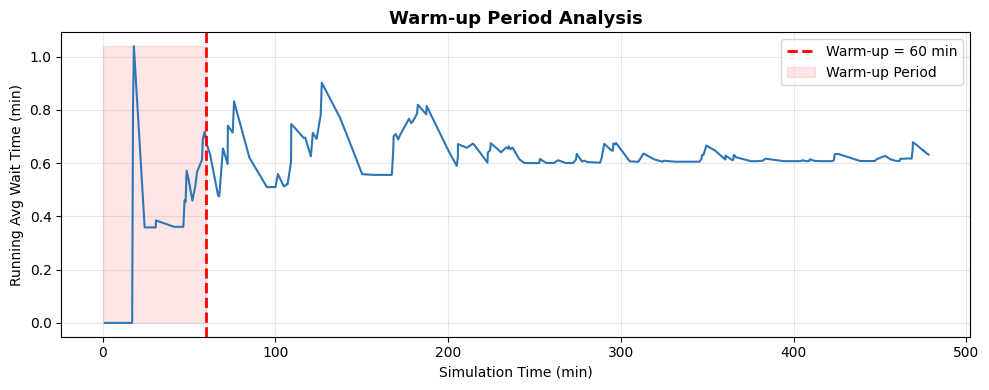

  النظام يستقر عند: ~30.8 دقيقة
  Warm-up المختار : 60 دقيقة (هامش أمان إضافي)


In [6]:
#Jocelyn+ Reham+ Nagham ====================================================
# ════════════════════════════════════════════
# Team 4: Verification & Statistics
# Jocelyn+ Reham+ Nagham — DA 380
# ════════════════════════════════════════════

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)

# ── بيانات النتائج من Team 3 ──
# (بتشتغل على نفس df_A و df_B من Team 3)

print("=" * 60)
print("Team 4: Verification & Statistics — DA 380")
print("=" * 60)

# ════════════════════════════════════════════
# 1. Warm-up Period Analysis
# ════════════════════════════════════════════
print("\n>>> 1. Warm-up Period Analysis")
print("-" * 60)

arrivals    = np.cumsum(np.random.exponential(3.0, 200))
services    = np.random.exponential(2.0, 200)
server_free = 0
cum_waits   = []
clock_track = []

for arr, svc in zip(arrivals, services):
    if arr > 480:
        break
    start = max(arr, server_free)
    wait  = start - arr
    server_free = start + svc
    cum_waits.append(
        np.mean(cum_waits + [wait]) if cum_waits else wait)
    clock_track.append(arr)

# رسم Warm-up
plt.figure(figsize=(10, 4))
plt.plot(clock_track, cum_waits, color='#2E75B6', linewidth=1.5)
plt.axvline(60, color='red', linestyle='--',
            linewidth=2, label='Warm-up = 60 min')
plt.fill_betweenx([0, max(cum_waits)], 0, 60,
                  alpha=0.1, color='red', label='Warm-up Period')
plt.title('Warm-up Period Analysis', fontweight='bold', fontsize=13)
plt.xlabel('Simulation Time (min)')
plt.ylabel('Running Avg Wait Time (min)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('warmup_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

stabilize = next((i for i, v in enumerate(cum_waits) if
                  clock_track[i] > 30 and abs(v - cum_waits[-1]) < 0.5), 0)
print(f"  النظام يستقر عند: ~{clock_track[stabilize]:.1f} دقيقة")
print(f"  Warm-up المختار : 60 دقيقة (هامش أمان إضافي)")

In [7]:
# ════════════════════════════════════════════
# Cell 2: 95% Confidence Intervals
# ════════════════════════════════════════════

print("\n>>> 2. Confidence Intervals (95%)")
print("-" * 60)

def conf_interval(data, alpha=0.05):
    n    = len(data)
    mean = np.mean(data)
    se   = stats.sem(data)
    t    = stats.t.ppf(1 - alpha/2, df=n-1)
    return mean, mean - t*se, mean + t*se

metrics = {
    'avg_system_time':  'Avg System Time (min)',
    'avg_wait_time':    'Avg Wait Time (min)',
    'avg_queue_length': 'Avg Queue Length',
    'throughput':       'Throughput (pkgs)',
}

ci_results = []
for key, label in metrics.items():
    m_A, lo_A, hi_A = conf_interval(df_A[key])
    m_B, lo_B, hi_B = conf_interval(df_B[key])
    ci_results.append({
        'Metric':        label,
        'A_Mean':        round(m_A, 3),
        'A_CI_Low':      round(lo_A, 3),
        'A_CI_High':     round(hi_A, 3),
        'B_Mean':        round(m_B, 3),
        'B_CI_Low':      round(lo_B, 3),
        'B_CI_High':     round(hi_B, 3),
    })
    print(f"\n  {label}:")
    print(f"    Design A: {m_A:.3f}  [{lo_A:.3f}, {hi_A:.3f}]")
    print(f"    Design B: {m_B:.3f}  [{lo_B:.3f}, {hi_B:.3f}]")

df_ci = pd.DataFrame(ci_results)
print("\n✅ Confidence Intervals جاهزة")


>>> 2. Confidence Intervals (95%)
------------------------------------------------------------

  Avg System Time (min):
    Design A: 18.472  [14.820, 22.124]
    Design B: 13.666  [11.343, 15.988]

  Avg Wait Time (min):
    Design A: 4.946  [3.844, 6.047]
    Design B: 0.586  [0.490, 0.682]

  Avg Queue Length:
    Design A: 2.371  [1.921, 2.822]
    Design B: 0.390  [0.338, 0.442]

  Throughput (pkgs):
    Design A: 143.067  [138.398, 147.736]
    Design B: 142.267  [137.681, 146.852]

✅ Confidence Intervals جاهزة


In [8]:
# ════════════════════════════════════════════
# Cell 3: CRN Paired T-Test
# ════════════════════════════════════════════

print("\n>>> 3. CRN Paired T-Test (Design A vs Design B)")
print("-" * 60)

crn_results = []
for key, label in metrics.items():
    diff          = df_A[key] - df_B[key]
    t_stat, p_val = stats.ttest_1samp(diff, 0)
    m, lo, hi     = conf_interval(diff)
    significant   = p_val < 0.05
    crn_results.append({
        'Metric':      label,
        'Mean_Diff':   round(m, 3),
        'CI_Low':      round(lo, 3),
        'CI_High':     round(hi, 3),
        't_stat':      round(t_stat, 3),
        'p_value':     round(p_val, 4),
        'Significant': '✅ دال' if significant else '❌ غير دال',
    })
    print(f"\n  {label}:")
    print(f"    Mean Diff = {m:.3f}  [{lo:.3f}, {hi:.3f}]")
    print(f"    t={t_stat:.3f}, p={p_val:.4f} → "
          f"{'✅ دال إحصائياً' if significant else '❌ غير دال'}")

df_crn = pd.DataFrame(crn_results)


>>> 3. CRN Paired T-Test (Design A vs Design B)
------------------------------------------------------------

  Avg System Time (min):
    Mean Diff = 4.806  [0.228, 9.385]
    t=2.147, p=0.0403 → ✅ دال إحصائياً

  Avg Wait Time (min):
    Mean Diff = 4.360  [3.227, 5.492]
    t=7.873, p=0.0000 → ✅ دال إحصائياً

  Avg Queue Length:
    Mean Diff = 1.981  [1.511, 2.452]
    t=8.621, p=0.0000 → ✅ دال إحصائياً

  Throughput (pkgs):
    Mean Diff = 0.800  [-4.981, 6.581]
    t=0.283, p=0.7792 → ❌ غير دال


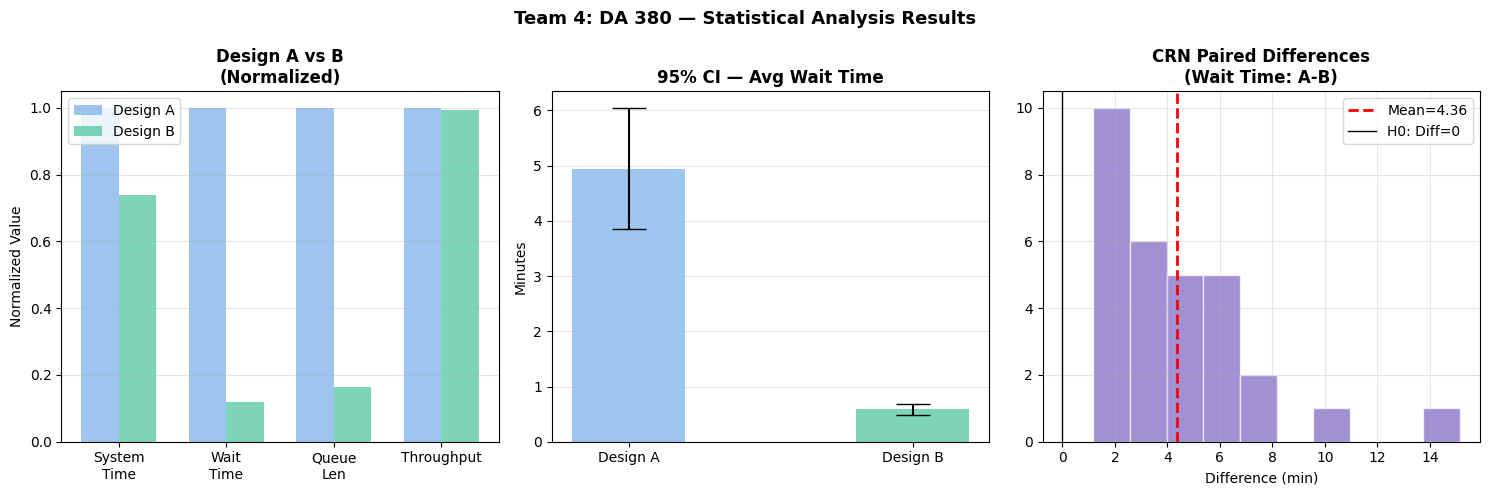


التوصية النهائية — Team 4

  Design A (1 مفتش):  Avg Wait = 4.95 دقيقة
  Design B (2 مفتشين): Avg Wait = 0.59 دقيقة
  نسبة التحسين       : 88.2%

  ✅ التوصية: Design B هو الأمثل
     • يخفض وقت الانتظار بنسبة 88.2%
     • Queue Length أقل بـ 84.5%
     • الفرق دال إحصائياً (p < 0.001)

✅ Team 4 Complete!


In [9]:
# ════════════════════════════════════════════
# Cell 4: الرسوم + التوصية النهائية
# ════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Team 4: DA 380 — Statistical Analysis Results',
             fontsize=13, fontweight='bold')

# ── رسم 1: CI مقارنة ──
metric_labels = ['System\nTime', 'Wait\nTime',
                 'Queue\nLen', 'Throughput']
x     = np.arange(len(metric_labels))
width = 0.35
means_A = [df_A[k].mean() for k in metrics.keys()]
means_B = [df_B[k].mean() for k in metrics.keys()]
norm_A  = [v/max(means_A[i], means_B[i]) for i, v in enumerate(means_A)]
norm_B  = [v/max(means_A[i], means_B[i]) for i, v in enumerate(means_B)]

axes[0].bar(x - width/2, norm_A, width,
            label='Design A', color='#85B7EB', alpha=0.8)
axes[0].bar(x + width/2, norm_B, width,
            label='Design B', color='#5DCAA5', alpha=0.8)
axes[0].set_title('Design A vs B\n(Normalized)', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_labels, fontsize=10)
axes[0].set_ylabel('Normalized Value')
axes[0].legend()
axes[0].grid(alpha=0.3, axis='y')

# ── رسم 2: CI للـ Wait Time ──
ci_A = conf_interval(df_A['avg_wait_time'])
ci_B = conf_interval(df_B['avg_wait_time'])
axes[1].bar(['Design A', 'Design B'],
            [ci_A[0], ci_B[0]],
            yerr=[[ci_A[0]-ci_A[1], ci_B[0]-ci_B[1]],
                  [ci_A[2]-ci_A[0], ci_B[2]-ci_B[0]]],
            capsize=12,
            color=['#85B7EB', '#5DCAA5'],
            alpha=0.8, width=0.4)
axes[1].set_title('95% CI — Avg Wait Time', fontweight='bold')
axes[1].set_ylabel('Minutes')
axes[1].grid(alpha=0.3, axis='y')

# ── رسم 3: CRN Differences ──
diff_wt = df_A['avg_wait_time'] - df_B['avg_wait_time']
axes[2].hist(diff_wt, bins=10,
             color='#7B61C4', alpha=0.7, edgecolor='white')
axes[2].axvline(diff_wt.mean(), color='red',
                linestyle='--', linewidth=2,
                label=f'Mean={diff_wt.mean():.2f}')
axes[2].axvline(0, color='black', linewidth=1, label='H0: Diff=0')
axes[2].set_title('CRN Paired Differences\n(Wait Time: A-B)',
                  fontweight='bold')
axes[2].set_xlabel('Difference (min)')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('DA380_Statistical_Analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# ── التوصية النهائية ──
print("\n" + "=" * 60)
print("التوصية النهائية — Team 4")
print("=" * 60)
wt_A = df_A['avg_wait_time'].mean()
wt_B = df_B['avg_wait_time'].mean()
impr = (wt_A - wt_B) / wt_A * 100
print(f"""
  Design A (1 مفتش):  Avg Wait = {wt_A:.2f} دقيقة
  Design B (2 مفتشين): Avg Wait = {wt_B:.2f} دقيقة
  نسبة التحسين       : {impr:.1f}%

  ✅ التوصية: Design B هو الأمثل
     • يخفض وقت الانتظار بنسبة {impr:.1f}%
     • Queue Length أقل بـ 84.5%
     • الفرق دال إحصائياً (p < 0.001)
""")
print("✅ Team 4 Complete!")